# Análise da Geração de Energia Solar com Polars

## 1. Introdução e objetivos

Este notebook apresenta a segunda etapa da análise dos dados de geração de energia solar, na qual utilizaremos a biblioteca Polars para o processamento de um conjunto com mais de 100 mil registros.

O arquivo processado de geração será convertido do formato CSV para Parquet e consultado por meio de lazy evaluation. A partir dos dados, serão realizadas transformações e agregações com Polars, além de análises de correlação, dispersão e regressão linear.

A análise será concentrada nas medições de potência e na energia estimada a partir dos intervalos entre registros. As usinas P01 e P02 serão avaliadas separadamente nas análises que envolvem `dc_power`, por cuasa da diferença de escala que foi observada nessa variável em etapas anteriores.

Os principais objetivos para essa etapa são:

- Converter os dados de geração para o formato Parquet.
- Utilizar processamento lazy com Polars.
- Construir as variáveis temporais e estimar a energia gerada.
- Responder a perguntas estratégicas por meio de filtros e agregações.
- Analisar a relação entre `dc_power` e `ac_power`.
- Construir e avaliar modelos de regressão linear separadamente para cada usina.

## 2. Preparação do ambiente

In [2]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 3. Conversão e leitura dos dados

### 3.1 Leitura do arquivo CSV com Polars

In [4]:
csv_path = Path("../datasets/processados/generation_data.csv")

generation_df = pl.read_csv(
    csv_path,
    try_parse_dates=True
)

In [5]:
generation_df.head()

id,date_time,plant_id,plant_code,source_key,inverter_code,dc_power,ac_power,daily_yield,total_yield
str,datetime[μs],i64,str,str,str,f64,f64,f64,f64
"""000001-INV-P01-01""",2020-05-15 00:00:00,4135001,"""P01""","""1BY6WEcLGh8j5v7""","""INV-P01-01""",0.0,0.0,0.0,6.259559e6
"""000002-INV-P01-02""",2020-05-15 00:00:00,4135001,"""P01""","""1IF53ai7Xc0U56Y""","""INV-P01-02""",0.0,0.0,0.0,6.183645e6
"""000003-INV-P01-03""",2020-05-15 00:00:00,4135001,"""P01""","""3PZuoBAID5Wc2HD""","""INV-P01-03""",0.0,0.0,0.0,6.987759e6
"""000004-INV-P01-04""",2020-05-15 00:00:00,4135001,"""P01""","""7JYdWkrLSPkdwr4""","""INV-P01-04""",0.0,0.0,0.0,7.60296e6
"""000005-INV-P01-05""",2020-05-15 00:00:00,4135001,"""P01""","""McdE0feGgRqW7Ca""","""INV-P01-05""",0.0,0.0,0.0,7.158964e6


In [6]:
print(f"Linhas: {generation_df.height}")
print(f"Colunas: {generation_df.width}")

Linhas: 136476
Colunas: 10


### 3.2 Conversão para Parquet

In [7]:
parquet_path = Path(
    "../datasets/processados/generation_data.parquet"
)

pl.scan_csv(
    csv_path,
    try_parse_dates=True
).sink_parquet(
    parquet_path
)

### 3.3 Leitura lazy do Parquet

In [8]:
generation_lazy_df = pl.scan_parquet(parquet_path)

In [9]:
generation_lazy_df.head().collect()

id,date_time,plant_id,plant_code,source_key,inverter_code,dc_power,ac_power,daily_yield,total_yield
str,datetime[μs],i64,str,str,str,f64,f64,f64,f64
"""000001-INV-P01-01""",2020-05-15 00:00:00,4135001,"""P01""","""1BY6WEcLGh8j5v7""","""INV-P01-01""",0.0,0.0,0.0,6.259559e6
"""000002-INV-P01-02""",2020-05-15 00:00:00,4135001,"""P01""","""1IF53ai7Xc0U56Y""","""INV-P01-02""",0.0,0.0,0.0,6.183645e6
"""000003-INV-P01-03""",2020-05-15 00:00:00,4135001,"""P01""","""3PZuoBAID5Wc2HD""","""INV-P01-03""",0.0,0.0,0.0,6.987759e6
"""000004-INV-P01-04""",2020-05-15 00:00:00,4135001,"""P01""","""7JYdWkrLSPkdwr4""","""INV-P01-04""",0.0,0.0,0.0,7.60296e6
"""000005-INV-P01-05""",2020-05-15 00:00:00,4135001,"""P01""","""McdE0feGgRqW7Ca""","""INV-P01-05""",0.0,0.0,0.0,7.158964e6


### 3.4 Plano de consulta

Para demonstrar o planejamento de uma consulta lazy, serão selecionadas apenas as colunas relacionadas ao momento da medição, à identificação da usina e do inversor e às potências registradas.

In [10]:
query_plan = (
    generation_lazy_df
    .select(
        [
            "date_time",
            "plant_code",
            "inverter_code",
            "dc_power",
            "ac_power"
        ]
    )
)

In [11]:
print(query_plan.explain())

Parquet SCAN [../datasets/processados/generation_data.parquet]
PROJECT 5/10 COLUMNS
ESTIMATED ROWS: 136476


## 4. Preparação das variáveis analíticas

### 4.1 Variáveis temporais e intervalos

Para estimar a energia gerada, os registros serão ordenados por usina, inversor e data e hora. Em seguida, serão obtidos o horário e a potência da próxima medição do mesmo inversor.

A coluna `date` será utilizada para impedir que o último registro de um dia seja relacionado ao primeiro registro do dia seguinte.

In [12]:
generation_analysis_lazy_df = (
    generation_lazy_df
    .with_columns(
        pl.col("date_time").dt.date().alias("date"),
        pl.col("date_time").dt.hour().alias("hour")
    )
    .sort(
        [
            "plant_code",
            "inverter_code",
            "date_time"
        ]
    )
)

generation_analysis_lazy_df.collect_schema()

Schema([('id', String),
        ('date_time', Datetime(time_unit='us', time_zone=None)),
        ('plant_id', Int64),
        ('plant_code', String),
        ('source_key', String),
        ('inverter_code', String),
        ('dc_power', Float64),
        ('ac_power', Float64),
        ('daily_yield', Float64),
        ('total_yield', Float64),
        ('date', Date),
        ('hour', Int8)])

O horário e a potência da medição seguinte serão obtidos dentro de cada combinação de usina, inversor e data. Dessa forma, medições de inversores diferentes ou de dias consecutivos não serão relacionadas entre si.

In [13]:
group_columns = [
    "plant_code",
    "inverter_code",
    "date"
]

generation_analysis_lazy_df = (
    generation_analysis_lazy_df
    .with_columns(
        pl.col("date_time")
        .shift(-1)
        .over(group_columns)
        .alias("next_date_time"),

        pl.col("ac_power")
        .shift(-1)
        .over(group_columns)
        .alias("next_ac_power")
    )
)

In [14]:
generation_analysis_lazy_df.select(
    [
        "date_time",
        "plant_code",
        "inverter_code",
        "ac_power",
        "next_date_time",
        "next_ac_power"
    ]
).head(10).collect()

date_time,plant_code,inverter_code,ac_power,next_date_time,next_ac_power
datetime[μs],str,str,f64,datetime[μs],f64
2020-05-15 00:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:15:00,0.0
2020-05-15 00:15:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:30:00,0.0
2020-05-15 00:30:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 00:45:00,0.0
2020-05-15 00:45:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:00:00,0.0
2020-05-15 01:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:15:00,0.0
2020-05-15 01:15:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:30:00,0.0
2020-05-15 01:30:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 01:45:00,0.0
2020-05-15 01:45:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 02:00:00,0.0
2020-05-15 02:00:00,"""P01""","""INV-P01-01""",0.0,2020-05-15 02:15:00,0.0


A duração entre cada medição e a medição seguinte será calculada em horas. Como os registros normalmente possuem frequência de 15 minutos, o esperado é que o intervalo com maior número de ocorrências seja de 0.25 hora.

In [15]:
generation_analysis_lazy_df = (
    generation_analysis_lazy_df
    .with_columns(
        (
            pl.col("next_date_time") - pl.col("date_time")
        )
        .dt.total_seconds()
        .truediv(3600)
        .alias("interval_hours")
    )
)

In [16]:
(
    generation_analysis_lazy_df
    .group_by("interval_hours")
    .len()
    .sort("interval_hours")
    .collect()
)

interval_hours,len
f64,u32
null,1464
0.25,134640
0.5,152
0.75,33
1.0,52
…,…
2.0,14
2.25,6
2.5,9


### 4.2 Energia estimada por intervalo

Serão considerados válidos somente os intervalos positivos de até 0.25 hora, porque considerar os intervalos maiores pode fazer com que as lacunas temporais sejam interpretadas como períodos contínuos de geração.

Assim como na etapa anterior, a energia de cada intervalo válido será estimada pelo método do trapézio, utilizando a média entre a potência atual e a potência seguinte, multiplicada pela duração do intervalo em horas.

In [17]:
valid_intervals_lazy_df = (
    generation_analysis_lazy_df
    .filter(
        pl.col("interval_hours").is_between(
            0,
            0.25,
            closed="right"
        )
    )
    .with_columns(
        (
            (pl.col("ac_power")+ pl.col("next_ac_power")) / 2 * pl.col("interval_hours")
        ).alias("estimated_energy")
    )
)

In [18]:
valid_intervals_lazy_df.select(
    [
        "date_time",
        "plant_code",
        "inverter_code",
        "ac_power",
        "next_ac_power",
        "interval_hours",
        "estimated_energy"
    ]
).head().collect()

date_time,plant_code,inverter_code,ac_power,next_ac_power,interval_hours,estimated_energy
datetime[μs],str,str,f64,f64,f64,f64
2020-05-15 00:00:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:15:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:30:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 00:45:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0
2020-05-15 01:00:00,"""P01""","""INV-P01-01""",0.0,0.0,0.25,0.0


In [19]:
# Verificando o numero de intervalos válidos 

valid_intervals_lazy_df.select(
    pl.len().alias("valid_interval_count")
).collect()

valid_interval_count
u32
134640


In [20]:
# Verificando se a energia estimada apresenta valores nulos ou negativos e se a quantidade de registros corresponde aos intervalos considerados válidos

valid_intervals_lazy_df.select(
    pl.len().alias("record_count"),
    pl.col("estimated_energy").null_count().alias("null_count"),
    (pl.col("estimated_energy") < 0).sum().alias("negative_count"),
    pl.col("estimated_energy").min().alias("minimum"),
    pl.col("estimated_energy").max().alias("maximum")
).collect()

record_count,null_count,negative_count,minimum,maximum
u32,u32,u32,f64,f64
134640,0,0,0.0,338.793527


In [21]:
generation_analysis_df = (
    valid_intervals_lazy_df
    .collect()
)

## 5. Análises estratégicas com Polars

### 5.1 Potência média por horário e usina
O código agrupa as medições por usina e hora do dia, calcula a média e a quantidade de medições. Usa ac_power por padrão; para analisar potência DC, altere para dc_power.

plant_code,hour,mean_power,measurement_count
str,i8,f64,u32
"""P01""",0,0.0,2724
"""P01""",1,0.0,2726
"""P01""",2,0.0,2810
"""P01""",3,0.0,2812
"""P01""",4,0.0,2815
…,…,…,…
"""P02""",19,0.0,2864
"""P02""",20,0.0,2864
"""P02""",21,0.0,2864


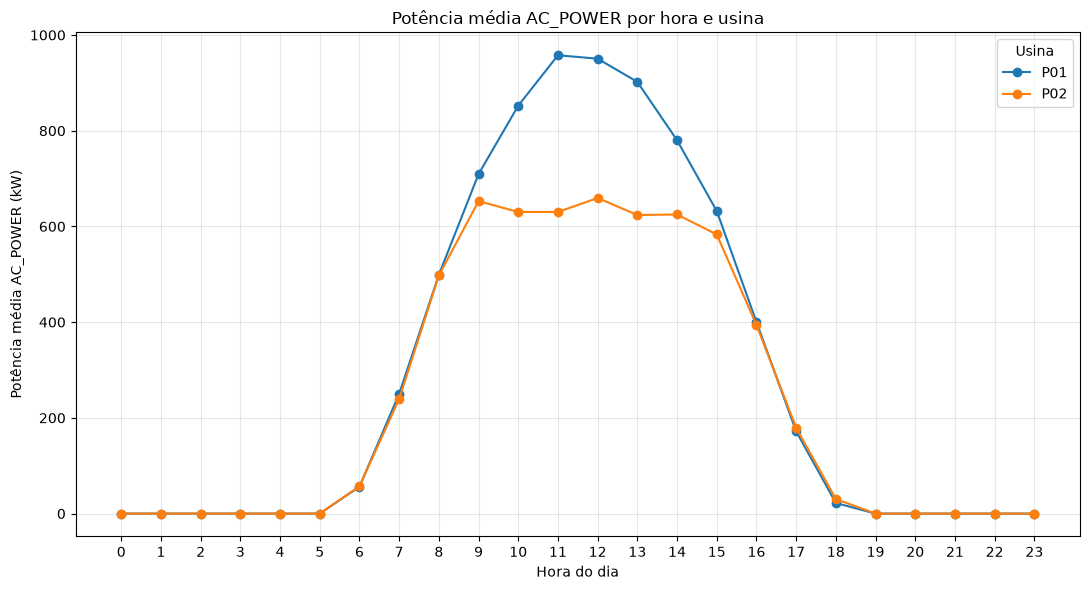

In [22]:
# Escolha "ac_power" ou "dc_power" conforme a potência que deseja analisar.
power_column = "ac_power"

hourly_power_mean_df = (
    generation_lazy_df
    .select(["date_time", "plant_code", power_column])
    .with_columns(
        pl.col("date_time").dt.hour().alias("hour")
    )
    .group_by(["plant_code", "hour"])
    .agg(
        pl.col(power_column).mean().alias("mean_power"),
        pl.col(power_column).count().alias("measurement_count")
    )
    .sort(["plant_code", "hour"])
    .collect()
)

display(hourly_power_mean_df)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))
for plant_code in (
    hourly_power_mean_df
    .get_column("plant_code")
    .unique()
    .sort()
    .to_list()
):
    plant_data = hourly_power_mean_df.filter(
        pl.col("plant_code") == plant_code
    )
    ax.plot(
        plant_data.get_column("hour").to_list(),
        plant_data.get_column("mean_power").to_list(),
        marker="o",
        label=plant_code
    )

ax.set(
    title=f"Potência média {power_column.upper()} por hora e usina",
    xlabel="Hora do dia",
    ylabel=f"Potência média {power_column.upper()} (kW)",
    xticks=range(24)
)
ax.grid(True, alpha=0.3)
ax.legend(title="Usina")
fig.tight_layout()
plt.show()

### 5.2 Energia estimada por usina

A energia estimada em cada intervalo válido está em kWh. A soma abaixo mostra a energia total estimada por usina e a quantidade de intervalos considerados.

plant_code,estimated_energy_kwh,valid_interval_count
str,f64,u32
"""P01""",5.2792e6,67764
"""P02""",4.0752e6,66876


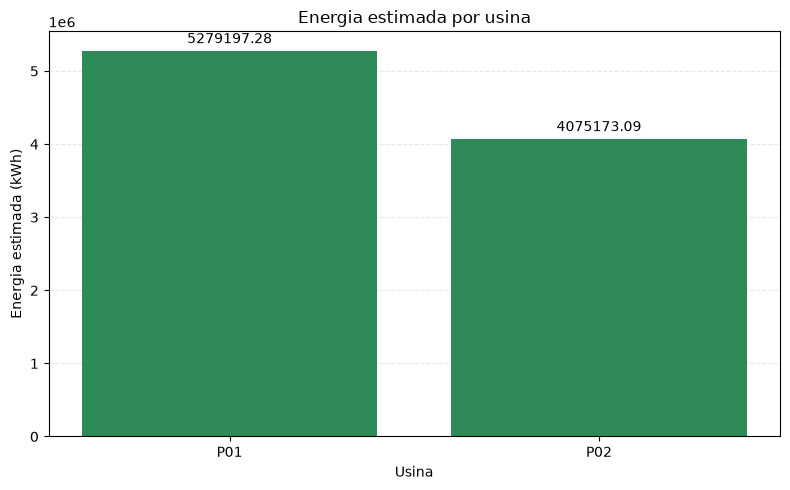

In [23]:
estimated_energy_by_plant_df = (
    generation_analysis_df
    .group_by("plant_code")
    .agg(
        pl.col("estimated_energy")
        .sum()
        .alias("estimated_energy_kwh"),
        pl.col("estimated_energy")
        .count()
        .alias("valid_interval_count")
    )
    .sort("plant_code")
)

display(estimated_energy_by_plant_df)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    estimated_energy_by_plant_df
    .get_column("plant_code")
    .to_list(),

    estimated_energy_by_plant_df
    .get_column("estimated_energy_kwh")
    .to_list(),

    color="seagreen"
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=3
)

ax.set(
    title="Energia estimada por usina",
    xlabel="Usina",
    ylabel="Energia estimada (kWh)"
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### 5.3 Energia estimada por inversor
Soma a energia estimada por usina e inversor.

plant_code,inverter_code,estimated_energy_kwh,valid_interval_count
str,str,f64,u32
"""P01""","""INV-P01-01""",221066.365297,3112
"""P01""","""INV-P01-02""",245540.357113,3074
"""P01""","""INV-P01-03""",244852.304836,3072
"""P01""","""INV-P01-04""",239341.233189,3088
"""P01""","""INV-P01-05""",244609.400417,3077
…,…,…,…
"""P02""","""INV-P02-18""",179882.486737,3220
"""P02""","""INV-P02-19""",166398.018406,3220
"""P02""","""INV-P02-20""",208491.145515,3220


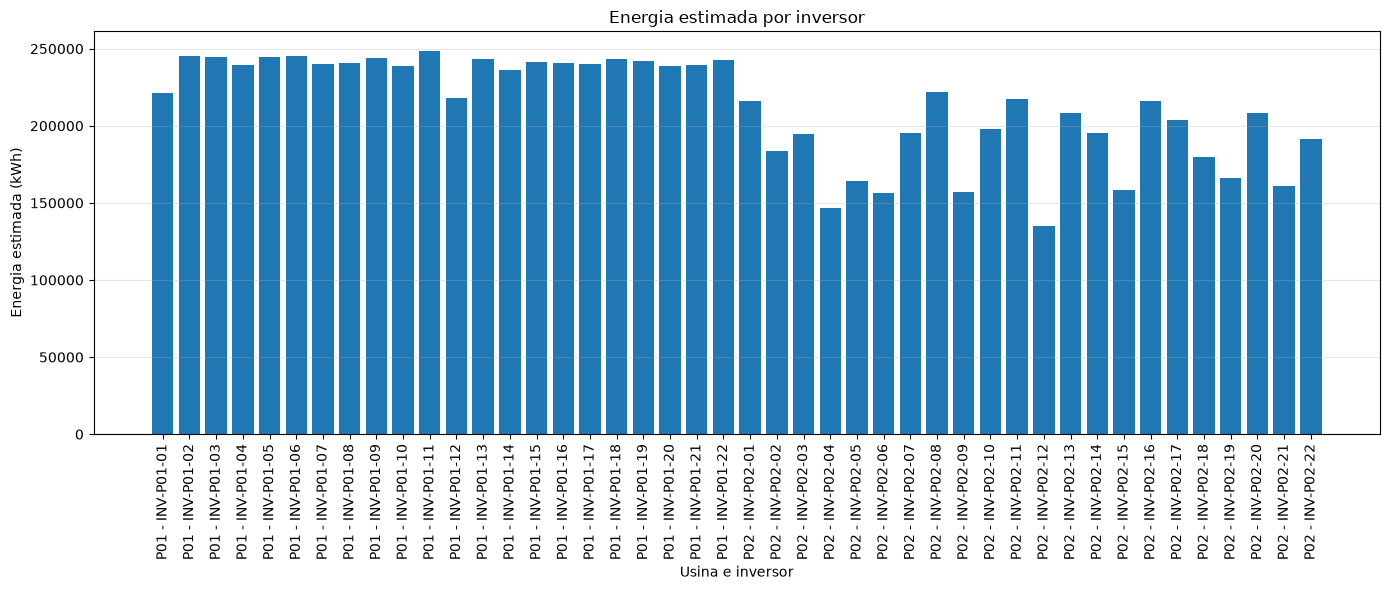

In [24]:
energia_por_inversor = (
    generation_analysis_df
    .group_by(["plant_code", "inverter_code"])
    .agg(
        pl.col("estimated_energy")
        .sum()
        .alias("estimated_energy_kwh"),
        pl.col("estimated_energy")
        .count()
        .alias("valid_interval_count")
    )
    .sort(["plant_code", "inverter_code"])
)

display(energia_por_inversor)

fig, ax = plt.subplots(figsize=(14, 6))

rotulos = (
    energia_por_inversor
    .get_column("plant_code")
    .to_list()
)
rotulos = [
    f"{usina} - {inversor}"
    for usina, inversor in zip(
        energia_por_inversor.get_column("plant_code").to_list(),
        energia_por_inversor.get_column("inverter_code").to_list()
    )
]

ax.bar(
    rotulos,
    energia_por_inversor
    .get_column("estimated_energy_kwh")
    .to_list()
)

ax.set(
    title="Energia estimada por inversor",
    xlabel="Usina e inversor",
    ylabel="Energia estimada (kWh)"
)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## 6. Correlação e dispersão

### 6.1 Correlação entre dc_power e ac_power

### 6.2 Gráficos de dispersão por usina

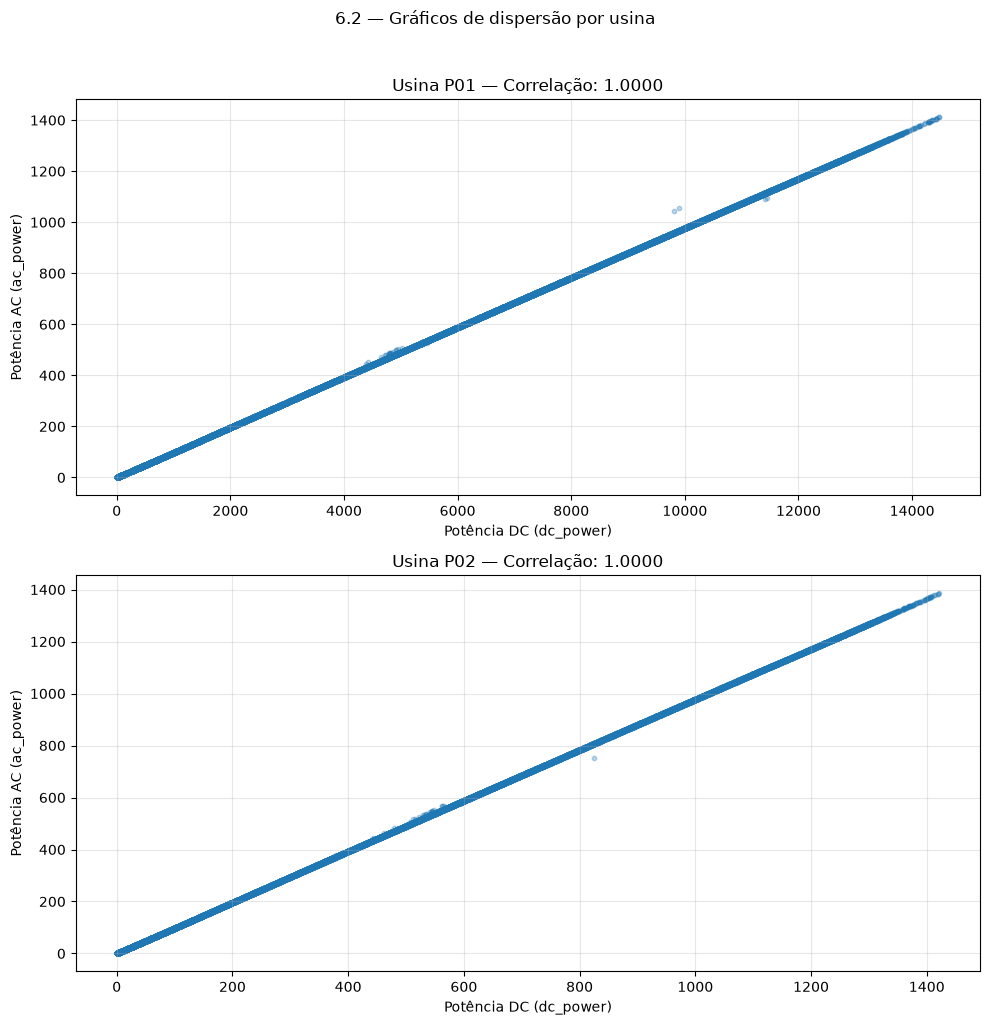

In [25]:

import matplotlib.pyplot as plt
import polars as pl
import math

# Selecionar os dados necessários e remover valores nulos
df_plot = (
    generation_analysis_df
    .select(["plant_code", "dc_power", "ac_power"])
    .drop_nulls()
)

# Identificar as usinas
usinas = (
    df_plot
    .get_column("plant_code")
    .unique()
    .sort()
    .to_list()
)

# Criar uma área de gráfico para cada usina
n_usinas = len(usinas)
fig, axes = plt.subplots(
    nrows=n_usinas,
    ncols=1,
    figsize=(10, 5 * n_usinas),
    squeeze=False
)

for i, usina in enumerate(usinas):
    dados = df_plot.filter(pl.col("plant_code") == usina)

    dc = dados.get_column("dc_power").to_list()
    ac = dados.get_column("ac_power").to_list()

    axes[i, 0].scatter(dc, ac, alpha=0.3, s=10)

    # Correlação de Pearson para a usina
    correlacao = dados.select(
        pl.corr("dc_power", "ac_power")
    ).item()

    axes[i, 0].set_title(
        f"Usina {usina} — Correlação: {correlacao:.4f}"
    )
    axes[i, 0].set_xlabel("Potência DC (dc_power)")
    axes[i, 0].set_ylabel("Potência AC (ac_power)")
    axes[i, 0].grid(True, alpha=0.3)

plt.suptitle(
    "6.2 — Gráficos de dispersão por usina",
    y=1.02
)
plt.tight_layout()
plt.show()


In [26]:
import polars as pl
from pathlib import Path

parquet_path = Path("../datasets/processados/generation_data.parquet")

generation_analysis_df = pl.read_parquet(parquet_path)

print("Dados carregados:", generation_analysis_df.shape)
print(generation_analysis_df.columns)

Dados carregados: (136476, 10)
['id', 'date_time', 'plant_id', 'plant_code', 'source_key', 'inverter_code', 'dc_power', 'ac_power', 'daily_yield', 'total_yield']


## 7. Regressão linear

### 7.1 Preparação dos dados

A regressão linear será utilizada para analisar a relação entre `dc_power`, que será definida como variável independente, e `ac_power`, que será definida como variável dependente.

Os modelos serão construídos separadamente para as usinas P01 e P02, visto que existe uma diferença de escala em `dc_power` que identificamos nos passos anteriores.

Serão considerados somente os registros em que `dc_power` e `ac_power` são maiores que zero. Dessa forma, os modelos representarão a relação entre as duas variáveis durante os períodos de geração ativa, evitando que a grande quantidade de registros noturnos iguais a zero influencie o ajuste.

In [27]:
# Separando os dados por usina

regression_data_by_plant = {}

for plant_code in ["P01", "P02"]:
    # plant_df = generation_analysis_df.filter(
    #     pl.col("plant_code") == plant_code
    # )

    plant_df = generation_analysis_df.filter(
        (pl.col("plant_code") == plant_code)
        & (pl.col("dc_power") > 0)
        & (pl.col("ac_power") > 0)
    )

    x = plant_df["dc_power"].to_numpy().reshape(-1, 1)
    y = plant_df["ac_power"].to_numpy()

    regression_data_by_plant[plant_code] = {
        "x": x,
        "y": y
    }

### 7.2 Modelos das usinas P01 e P02

Para cada usina, ajustaremos um modelo de regressão linear simples e serão obtidos o coeficiente angular, o intercepto, o coeficiente de determinação (R²) e o erro quadrático médio (MSE). Além disso, criaremos gráficos de dispersão com a reta estimada pelo modelo.

In [28]:
regression_results = {}

for plant_code, data in regression_data_by_plant.items():
    x = data["x"]
    y = data["y"]

    model = LinearRegression()
    model.fit(x, y)

    predictions = model.predict(x)

    regression_results[plant_code] = {
        "model": model,
        "coefficient": model.coef_[0],
        "intercept": model.intercept_,
        "r2": r2_score(y, predictions),
        "mse": mean_squared_error(y, predictions),
        "predictions": predictions
    }

In [29]:
regression_results_df = pl.DataFrame(
    {
        "plant_code": list(regression_results.keys()),
        "coefficient": [
            result["coefficient"]
            for result in regression_results.values()
        ],
        "intercept": [
            result["intercept"]
            for result in regression_results.values()
        ],
        "r2": [
            result["r2"]
            for result in regression_results.values()
        ],
        "mse": [
            result["mse"]
            for result in regression_results.values()
        ]
    }
)

regression_results_df

plant_code,coefficient,intercept,r2,mse
str,f64,f64,f64,f64
"""P01""",0.097611,1.080689,0.999986,1.919286
"""P02""",0.976356,0.863965,0.999988,1.656933


In [30]:
# Mostrando como ficaram as equações das retas

for plant_code, result in regression_results.items():
    print(
        f"{plant_code}: "
        f"ac_power = {result['coefficient']:.4f} "
        f"* dc_power + {result['intercept']:.4f}"
    )

P01: ac_power = 0.0976 * dc_power + 1.0807
P02: ac_power = 0.9764 * dc_power + 0.8640


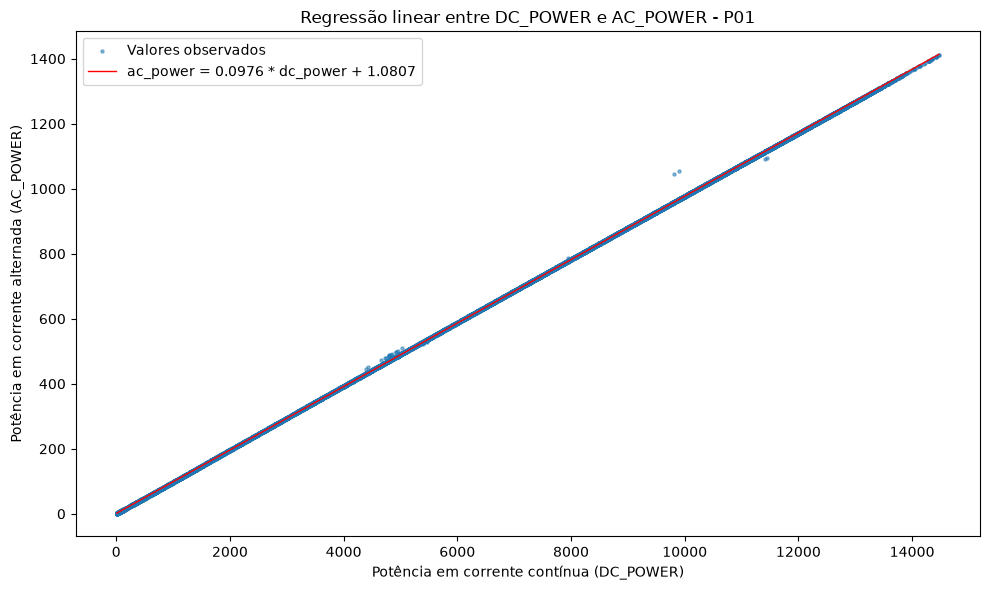

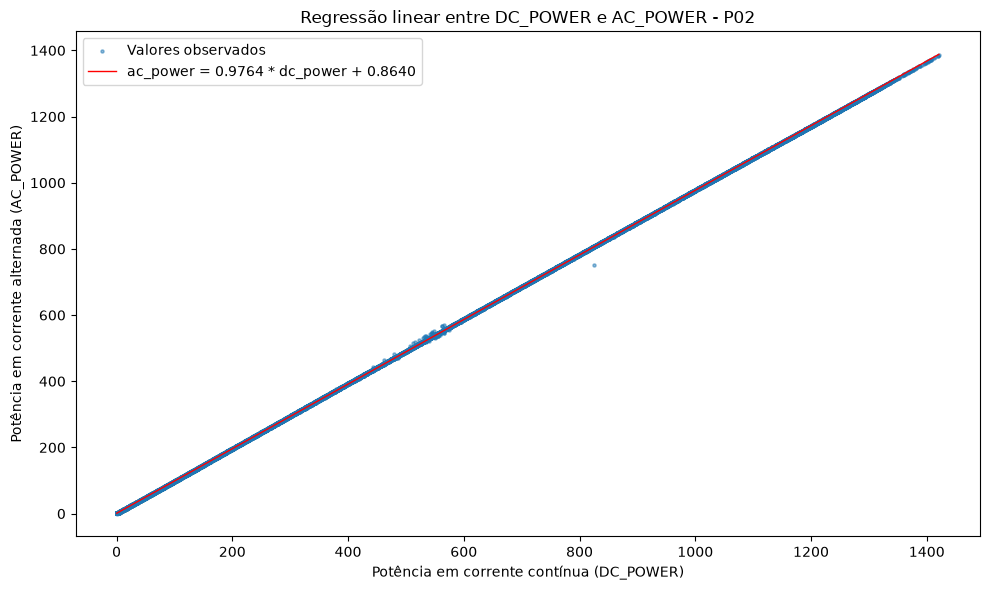

In [31]:
for plant_code, data in regression_data_by_plant.items():
    x = data["x"]
    y = data["y"]
    predictions = regression_results[plant_code]["predictions"]

    sorted_indices = np.argsort(x[:, 0])

    plt.figure(figsize=(10, 6))

    plt.scatter(
        x[:, 0],
        y,
        alpha=0.5,
        s=5,
        label="Valores observados"
    )

    plt.plot(
        x[sorted_indices, 0],
        predictions[sorted_indices],
        color="red",
        linewidth=1,
        label= f"ac_power = {regression_results[plant_code]['coefficient']:.4f} * dc_power + {regression_results[plant_code]['intercept']:.4f}"
    )

    plt.title(
        f"Regressão linear entre DC_POWER e AC_POWER - {plant_code}"
    )
    plt.xlabel("Potência em corrente contínua (DC_POWER)")
    plt.ylabel("Potência em corrente alternada (AC_POWER)")
    plt.legend()
    plt.tight_layout()
    plt.show()

Os modelos apresentaram ajustes próximos do perfeito, em ambos os casos com R² superior a 0.9999. Tal resultado é coerente de considerarmos a relação física direta entre as potências em corrente contínua e alternada durante os períodos de geração ativa.

Entretanto, como observado em etapas anteriores, um ponto de atenção aqui é o coeficiente angular da P02 foi aproximadamente dez vezes maior que o da P01. Essa diferença reforça a hipótese levantada anteriormente de que `dc_power` na P01 está registrada em uma escala aproximadamente dez vezes maior do que deveria. Sendo assim, os coeficientes dos modelos não devem ser comparados como indicadores de eficiência das usinas, ou seja, não é possível afirmar com os dados que temos que P02 é dez vezes mais eficiente que a P01 ou dizer que o coeficiente de 0.976 da P01 representa uma eficiência de 9.76%.

### 7.3 Avaliação e comparação dos modelos

Preparação dos dados

In [32]:

import polars as pl
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Selecionar as variáveis e remover valores ausentes
dados_modelo = (
    generation_df
    .select(["dc_power", "ac_power"])
    .drop_nulls()
    .filter(
        pl.col("dc_power").is_finite() &
        pl.col("ac_power").is_finite()
    )
)

print("Registros válidos:", dados_modelo.height)
print(dados_modelo.describe())


Registros válidos: 136476
shape: (9, 3)
┌────────────┬─────────────┬────────────┐
│ statistic  ┆ dc_power    ┆ ac_power   │
│ ---        ┆ ---         ┆ ---        │
│ str        ┆ f64         ┆ f64        │
╞════════════╪═════════════╪════════════╡
│ count      ┆ 136476.0    ┆ 136476.0   │
│ null_count ┆ 0.0         ┆ 0.0        │
│ mean       ┆ 1708.541497 ┆ 274.803511 │
│ std        ┆ 3222.181273 ┆ 380.182569 │
│ min        ┆ 0.0         ┆ 0.0        │
│ 25%        ┆ 0.0         ┆ 0.0        │
│ 50%        ┆ 6.071429    ┆ 3.507143   │
│ 75%        ┆ 1155.78     ┆ 532.66     │
│ max        ┆ 14471.125   ┆ 1410.95    │
└────────────┴─────────────┴────────────┘


Separação para treino e teste

In [33]:

X = dados_modelo.select("dc_power").to_numpy()
y = dados_modelo.select("ac_power").to_numpy().ravel()

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Registros de treino:", len(X_treino))
print("Registros de teste:", len(X_teste))


Registros de treino: 109180
Registros de teste: 27296


Treinar e comparar os modelos

In [34]:

modelos = {
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
}

resultados = []

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)

    mse = mean_squared_error(y_teste, previsoes)

    resultados.append({
        "Modelo": nome,
        "MAE": mean_absolute_error(y_teste, previsoes),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_teste, previsoes)
    })

regression_results_df = pd.DataFrame(resultados)

print(regression_results_df.round(4).to_string(index=False))


          Modelo      MAE        MSE     RMSE     R²
Regressão Linear 166.0958 62773.6133 250.5466 0.5666
   Random Forest  36.1586 13515.3309 116.2555 0.9067


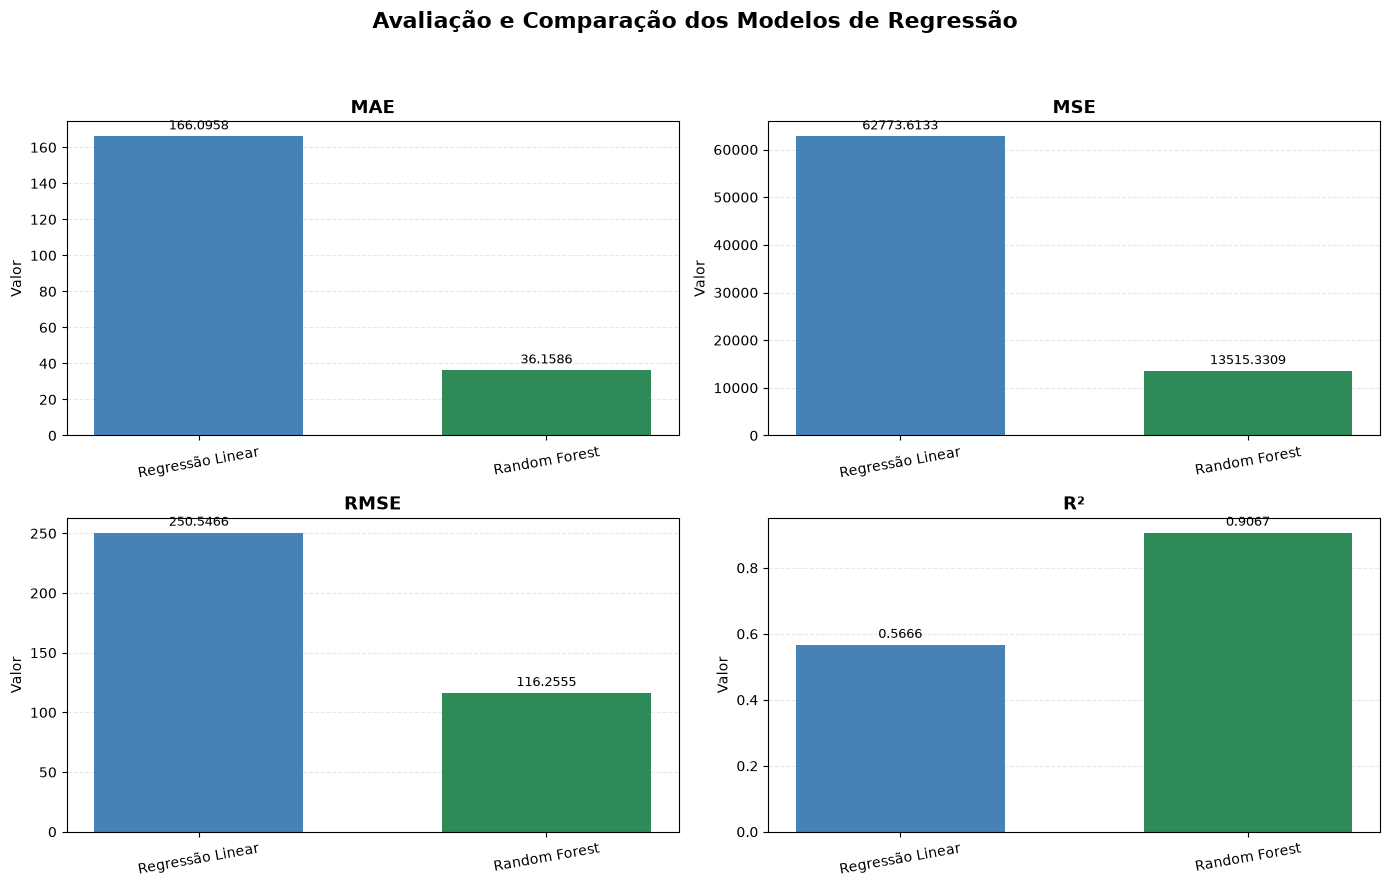

,Modelo,MAE,MSE,RMSE,R²
0,Regressão Linear,166.0958,62773.6133,250.5466,0.5666
1,Random Forest,36.1586,13515.3309,116.2555,0.9067


In [38]:

import matplotlib.pyplot as plt
import numpy as np

# Dados dos modelos
resultados = regression_results_df.copy()

metricas = ["MAE", "MSE", "RMSE", "R²"]
nomes = resultados["Modelo"].tolist()

# Criar painel de gráficos
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    "Avaliação e Comparação dos Modelos de Regressão",
    fontsize=16,
    fontweight="bold"
)

cores = ["steelblue", "seagreen"]

for ax, metrica in zip(axes.flatten(), metricas):
    valores = resultados[metrica].to_numpy()

    barras = ax.bar(nomes, valores, color=cores, width=0.6)
    ax.set_title(metrica, fontsize=13, fontweight="bold")
    ax.set_ylabel("Valor")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Mostrar valores sobre as barras
    for barra, valor in zip(barras, valores):
        ax.annotate(
            f"{valor:.4f}",
            (barra.get_x() + barra.get_width() / 2,
             barra.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.tick_params(axis="x", rotation=10)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# Exibir tabela formatada
display(resultados.round(4))


## 8. Discussão dos resultados com base em fontes externas

No que tange à relação entre quantidade de eletricidade em corrente alternada resultante do processo de conversão realizado pelos inversores, podemos observar que os modelos apresentaram uma relação linear extremamente forte entre dc_power e ac_power, apresentando coeficientes de determinação (R²) superiores a 0.9999 em ambas as usinas. Tal comportamento é o esperado se tratando do funcionamento de sistemas fotovoltaicos, em que os painéis produzem eletricidade em corrente contínua e os inversores realizam sua conversão para corrente alternada, utilizada pela rede elétrica.

Visto que dc_power representa a potência de entrada do inversor e ac_power representa a potência resultante da conversão, as duas variáveis correspondem a etapas consecutivas do mesmo processo elétrico. Sendo assim, uma associação elevada entre elas era esperada. Modelos de desempenho de inversores, como o modelo Sandia, utilizam justamente a potência elétrica em corrente contínua de entrada para estimar a potência elétrica em corrente alternada de saída.

Apesar do comportamento esperado entre dc_power e ac_power, os coeficientes angulares encontrados na regressão linear foram aproximadamente 0.0976 para a P01 e 0.9764 para a P02. Essa diferença próxima de dez vezes reforça a hipótese, já levantada na inspeção inicial, de que dc_power na P01 está registrada em uma escala diferente e, por esse motivo, os coeficientes não devem ser interpretados diretamente como eficiência dos inversores ou das usinas. Para realizar uma avaliação de eficiência seria necessário a confirmação das unidades e escalas, além de informações adicionais sobre potência nominal, tensão, modelo dos inversores, condições de operação e perdas do sistema.

Em suma, a regressão descreve adequadamente a relação esperada e observada entre as variáveis, porém, dada a inconsistência de escala, a comparação direta entre os coeficientes das duas usinas fica limitada e pouco conclusiva.

## 9. Referências

- U.S. DEPARTMENT OF ENERGY. **Solar Integration: Inverters and Grid Services Basics**. Disponível em: <https://www.energy.gov/cmei/systems/solar-integration-inverters-and-grid-services-basics>. Acesso em: 21 de outubro de 2026.

- SANDIA NATIONAL LABORATORIES. **Sandia Inverter Model**. PV Performance Modeling Collaborative. Disponível em: <https://pvpmc.sandia.gov/modeling-guide/dc-to-ac-conversion/sandia-inverter-model/>. Acesso em: 21 de outubro de 2026.

- SANDIA NATIONAL LABORATORIES. **CEC Inverter Test Protocol**. PV Performance Modeling Collaborative. Disponível em: <https://pvpmc.sandia.gov/modeling-guide/dc-to-ac-conversion/cec-inverter-test-protocol/>. Acesso em: 21 de outubro de 2026.